# IN_TOUCH v27 — Inference Notebook
### بتاخد فيديو → بترجع الـ sign اللي اتعمل
**المطلوب في نفس الفولدر:**
- `stgcn_best_v27_top60.pth`
- `stgcn_meta_v27_top60.pkl`
- `hand_landmarker.task`
- `pose_landmarker_heavy.task`
- `face_landmarker.task`

In [3]:
!pip install mediapipe==0.10.35

  You can safely remove it manually.



   ---------------------------------------- 0.0/10.9 MB ? eta -:--:--
   ---------------------------------------- 0.0/10.9 MB ? eta -:--:--
    --------------------------------------- 0.3/10.9 MB ? eta -:--:--
   - -------------------------------------- 0.5/10.9 MB 762.0 kB/s eta 0:00:14
   -- ------------------------------------- 0.8/10.9 MB 1.1 MB/s eta 0:00:10
   ----- ---------------------------------- 1.6/10.9 MB 1.7 MB/s eta 0:00:06
   ------- -------------------------------- 2.1/10.9 MB 1.9 MB/s eta 0:00:05
   --------- ------------------------------ 2.6/10.9 MB 2.0 MB/s eta 0:00:05
   ----------- ---------------------------- 3.1/10.9 MB 2.1 MB/s eta 0:00:04
   -------------- ------------------------- 3.9/10.9 MB 2.2 MB/s eta 0:00:04
   ---------------- ----------------------- 4.5/10.9 MB 2.3 MB/s eta 0:00:03
   ------------------ --------------------- 5.0/10.9 MB 2.3 MB/s eta 0:00:03
   -------------------- ------------------- 5.5/10.9 MB 2.4 MB/s eta 0:00:03
   --------------

In [13]:
!pip install torch==2.12.0

  Using cached torch-2.12.0-cp310-cp310-win_amd64.whl.metadata (31 kB)
  Using cached sympy-1.14.0-py3-none-any.whl.metadata (12 kB)
Using cached torch-2.12.0-cp310-cp310-win_amd64.whl (122.9 MB)
Using cached sympy-1.14.0-py3-none-any.whl (6.3 MB)

  Attempting uninstall: sympy

    Found existing installation: sympy 1.13.1

   ---------------------------------------- 0/2 [sympy]
   ---------------------------------------- 0/2 [sympy]
   ---------------------------------------- 0/2 [sympy]
   ---------------------------------------- 0/2 [sympy]
   ---------------------------------------- 0/2 [sympy]
   ---------------------------------------- 0/2 [sympy]
   ---------------------------------------- 0/2 [sympy]
   ---------------------------------------- 0/2 [sympy]
   ---------------------------------------- 0/2 [sympy]
    Uninstalling sympy-1.13.1:
   ---------------------------------------- 0/2 [sympy]
   ---------------------------------------- 0/2 [sympy]
   -----------------------

  You can safely remove it manually.



   -------------------- ------------------- 1/2 [torch]
   -------------------- ------------------- 1/2 [torch]
   -------------------- ------------------- 1/2 [torch]
   -------------------- ------------------- 1/2 [torch]
   -------------------- ------------------- 1/2 [torch]
   -------------------- ------------------- 1/2 [torch]
   -------------------- ------------------- 1/2 [torch]
   -------------------- ------------------- 1/2 [torch]
   -------------------- ------------------- 1/2 [torch]
   -------------------- ------------------- 1/2 [torch]
   -------------------- ------------------- 1/2 [torch]
   -------------------- ------------------- 1/2 [torch]
   -------------------- ------------------- 1/2 [torch]
   -------------------- ------------------- 1/2 [torch]
   -------------------- ------------------- 1/2 [torch]
   -------------------- ------------------- 1/2 [torch]
   -------------------- ------------------- 1/2 [torch]
   -------------------- ------------------- 1/2

In [1]:
# CELL 1 — Install & Imports
# pip install mediapipe opencv-python torch torchvision

import os, cv2, pickle, math
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
import mediapipe as mp
from mediapipe.tasks import python
from mediapipe.tasks.python import vision
import warnings; warnings.filterwarnings('ignore')

print('Imports OK ✓')

Imports OK ✓


In [2]:
import mediapipe, torch, cv2
print("mediapipe:", mediapipe.__version__)
print("torch    :", torch.__version__)
print("cv2      :", cv2.__version__)

mediapipe: 0.10.35
torch    : 2.12.0+cpu
cv2      : 4.11.0


In [1]:
import torch
print(torch.cuda.is_available())

False


In [2]:
import cv2
import numpy as np

cap = cv2.VideoCapture(r"C:\Users\Bavle\OneDrive\Desktop\now.mp4")
ok, frame = cap.read()
cap.release()

h, w = frame.shape[:2]
if h > w: frame = cv2.rotate(frame, cv2.ROTATE_90_CLOCKWISE)

sk = frame_to_skeleton(frame)
print("First 5 joints (dominant hand):")
print(sk[:5].round(4))
print("\nSum dominant:", np.abs(sk[:21]).sum().round(4))
print("Sum passive: ", np.abs(sk[21:42]).sum().round(4))

NameError: name 'frame_to_skeleton' is not defined

---
## ⚙️ CELL 2 — Config (عدّل المسارات هنا)

In [3]:
# CELL 2 — Config
# ─── عدّل المسارات دي بس ───────────────────────────────────────
PROJECT_ROOT   = r"C:\Users\Bavle\Downloads\intouch\intouch"   # ← فولدر المشروع
OUTPUT_DIR     = os.path.join(PROJECT_ROOT, "outputs_v27_top60")

SAVE_PATH_MODEL = os.path.join(OUTPUT_DIR,  "stgcn_best_v27_top60.pth")
SAVE_PATH_META  = os.path.join(OUTPUT_DIR,  "stgcn_meta_v27_top60.pkl")
MODEL_PATH      = os.path.join(PROJECT_ROOT, "hand_landmarker.task")
POSE_MODEL_PATH = os.path.join(PROJECT_ROOT, "pose_landmarker_heavy.task")
FACE_MODEL_PATH = os.path.join(PROJECT_ROOT, "face_landmarker.task")
# ────────────────────────────────────────────────────────────────

# ثوابت ثابتة — متغيّرهاش
MAX_NUM_HANDS = 2
FLIP_TEST     = False

# path check
for name, path in [
    ('Model .pth',        SAVE_PATH_MODEL),
    ('Meta  .pkl',        SAVE_PATH_META),
    ('Hand  landmarker',  MODEL_PATH),
    ('Pose  landmarker',  POSE_MODEL_PATH),
    ('Face  landmarker',  FACE_MODEL_PATH),
]:
    status = 'OK     ' if os.path.exists(path) else 'MISSING'
    print(f'  {status} | {name:20s} | {path}')

  OK      | Model .pth           | C:\Users\Bavle\Downloads\intouch\intouch\outputs_v27_top60\stgcn_best_v27_top60.pth
  OK      | Meta  .pkl           | C:\Users\Bavle\Downloads\intouch\intouch\outputs_v27_top60\stgcn_meta_v27_top60.pkl
  OK      | Hand  landmarker     | C:\Users\Bavle\Downloads\intouch\intouch\hand_landmarker.task
  OK      | Pose  landmarker     | C:\Users\Bavle\Downloads\intouch\intouch\pose_landmarker_heavy.task
  OK      | Face  landmarker     | C:\Users\Bavle\Downloads\intouch\intouch\face_landmarker.task


---
## 🧠 CELL 3 — Model Architecture

In [4]:
# CELL 3 — Model Architecture (ST-GCN v26/v27)
EPS = 1e-4

def bn_init(bn, s=1): nn.init.constant_(bn.weight, s); nn.init.constant_(bn.bias, 0)
def conv_init(c):
    nn.init.kaiming_normal_(c.weight, mode='fan_out')
    if c.bias is not None: nn.init.constant_(c.bias, 0)

def edge2mat(link, n):
    A = np.zeros((n, n))
    for i, j in link: A[i, j] = 1
    return A

def normalize_digraph(A):
    Dl = A.sum(0); Dn = np.zeros_like(A)
    for i in range(A.shape[0]):
        if Dl[i] > 0: Dn[i, i] = Dl[i] ** (-1)
    return A @ Dn

class Graph:
    def __init__(self):
        one = [(1,0),(2,1),(3,2),(4,3),(0,5),(5,6),(6,7),(7,8),
               (9,0),(10,9),(11,10),(12,11),(13,0),(14,13),(15,14),
               (16,15),(17,0),(18,17),(19,18),(20,19)]
        left = [(i+21, j+21) for i, j in one]
        self.num_node = 57
        self.inward = (
            one + left +
            [(4,8),(8,12),(12,16),(16,20),
             (4+21,8+21),(8+21,12+21),(12+21,16+21),(16+21,20+21)] +
            [(43,44),(43,45),(45,47),(44,46),(46,48),
             (43,49),(44,50),(42,43),(42,44)] +
            [(0,48),(21,47)] +
            [(51,52),(52,53),(53,54),(54,55),(51,42)]
        )
        n   = self.num_node
        I   = edge2mat([(i, i) for i in range(n)], n)
        In  = normalize_digraph(edge2mat(self.inward, n))
        Out = normalize_digraph(edge2mat([(j, i) for i, j in self.inward], n))
        self.A = np.stack([I, In, Out])

class ChannelAttention(nn.Module):
    def __init__(self, channels, ratio=4):
        super().__init__()
        hidden = max(channels // ratio, 8)
        self.fc = nn.Sequential(
            nn.Linear(channels, hidden), nn.ReLU(inplace=True),
            nn.Linear(hidden, channels), nn.Sigmoid(),
        )
    def forward(self, x):
        s = x.mean(dim=(2, 3))
        w = self.fc(s).unsqueeze(-1).unsqueeze(-1)
        return x * w

class SpatialAttention(nn.Module):
    def __init__(self, channels, num_joints=57):
        super().__init__()
        self.conv = nn.Conv2d(channels, 1, kernel_size=1)
        self.sigmoid = nn.Sigmoid()
    def forward(self, x):
        w = self.sigmoid(self.conv(x.mean(2, keepdim=True)))
        return x * w

class DropPath(nn.Module):
    def __init__(self, drop_prob=0.0):
        super().__init__(); self.drop_prob = drop_prob
    def forward(self, x):
        if not self.training or self.drop_prob == 0.0: return x
        keep = 1 - self.drop_prob
        shape = (x.shape[0],) + (1,) * (x.ndim - 1)
        random_tensor = torch.floor(torch.rand(shape, dtype=x.dtype, device=x.device) + keep)
        return x / keep * random_tensor

class GCN_Unit(nn.Module):
    def __init__(self, ic, oc, A):
        super().__init__()
        self.ns = A.shape[0]
        self.PA = nn.Parameter(torch.from_numpy(A.astype(np.float32)))
        self.convs = nn.ModuleList([nn.Conv2d(ic, oc, 1) for _ in range(self.ns)])
        self.bn = nn.BatchNorm2d(oc); self.relu = nn.ReLU(inplace=True)
        bn_init(self.bn)
        for c in self.convs: conv_init(c)
        self.res = (nn.Sequential(nn.Conv2d(ic, oc, 1), nn.BatchNorm2d(oc)) if ic != oc else None)
        if self.res: bn_init(self.res[1])
    def forward(self, x):
        y = sum(self.convs[i](torch.einsum('nctv,vw->nctw', x, self.PA[i])) for i in range(self.ns))
        res = self.res(x) if self.res is not None else x
        return self.relu(self.bn(y) + res)

class TCN_Unit(nn.Module):
    def __init__(self, ic, oc, stride=1, dropout=0.0):
        super().__init__()
        Ks = [3, 5, 9]; assert oc % len(Ks) == 0
        bc = oc // len(Ks)
        self.br = nn.ModuleList([nn.Conv2d(ic, bc, (k,1), (stride,1), ((k-1)//2,0)) for k in Ks])
        self.bn = nn.BatchNorm2d(bc * len(Ks)); self.dr = nn.Dropout(dropout)
        for c in self.br: conv_init(c); bn_init(self.bn)
    def forward(self, x):
        return self.dr(F.relu(self.bn(torch.cat([b(x) for b in self.br], dim=1)), inplace=True))

class StgcnBlock(nn.Module):
    def __init__(self, ic, oc, A, stride=1, residual=True, dropout=0.0, drop_path=0.0, use_attn=True):
        super().__init__()
        self.gcn = GCN_Unit(ic, oc, A); self.tcn = TCN_Unit(oc, oc, stride=stride, dropout=dropout)
        self.relu = nn.ReLU(inplace=True)
        self.ch_attn  = ChannelAttention(oc) if use_attn else nn.Identity()
        self.sp_attn  = SpatialAttention(oc) if use_attn else nn.Identity()
        self.drop_path = DropPath(drop_path) if drop_path > 0 else nn.Identity()
        if not residual:           self.res = lambda x: 0
        elif ic==oc and stride==1: self.res = lambda x: x
        else:                      self.res = TCN_Unit(ic, oc, stride=stride)
    def forward(self, x):
        out = self.tcn(self.gcn(x))
        out = self.ch_attn(out); out = self.sp_attn(out); out = self.drop_path(out)
        return self.relu(out + self.res(x))

class MultiHeadTemporalAttention(nn.Module):
    def __init__(self, C, num_heads=8):
        super().__init__()
        assert C % num_heads == 0
        self.num_heads = num_heads; self.head_dim = C // num_heads
        self.score_nets = nn.ModuleList([
            nn.Sequential(
                nn.Linear(self.head_dim, max(self.head_dim // 4, 4)), nn.Tanh(),
                nn.Linear(max(self.head_dim // 4, 4), 1),
            ) for _ in range(num_heads)
        ])
    def forward(self, x):
        N, C, T, V = x.shape
        g = x.mean(-1).permute(0, 2, 1)
        g_heads = g.view(N, T, self.num_heads, self.head_dim)
        x_heads = x.view(N, self.num_heads, self.head_dim, T, V)
        out_heads = []
        for h in range(self.num_heads):
            gh = g_heads[:, :, h, :]
            w  = torch.softmax(self.score_nets[h](gh).squeeze(-1), dim=-1)
            xh = x_heads[:, h, :, :, :]
            oh = (xh * w.unsqueeze(1).unsqueeze(-1)).sum(2)
            out_heads.append(oh)
        return torch.cat(out_heads, dim=1)

class StgcnModel(nn.Module):
    def __init__(self, in_channels, base_channels, num_class,
                 num_stages=7, inflate_stages=[3,5], down_stages=[3],
                 tcn_dropout=0.25, drop_path_rate=0.15,
                 num_heads_ta=8, cls_dropout=0.40, ch_ratio=2):
        super().__init__()
        G = Graph(); A = torch.tensor(G.A, dtype=torch.float32)
        self.data_bn = nn.BatchNorm1d(in_channels * G.num_node)
        blks, it, ch = [], 0, base_channels
        blks.append(StgcnBlock(in_channels, base_channels, A.clone().numpy(),
                               stride=1, residual=False, dropout=0.0, drop_path=0.0, use_attn=False))
        total_stages = num_stages - 1
        for i in range(2, num_stages + 1):
            st = 2 if i in down_stages else 1
            if i in inflate_stages: it += 1
            oc = int(base_channels * ch_ratio**it + EPS)
            dp_rate = drop_path_rate * (i - 2) / max(total_stages - 1, 1)
            blks.append(StgcnBlock(ch, oc, A.clone().numpy(), stride=st,
                                   dropout=tcn_dropout, drop_path=dp_rate, use_attn=True))
            ch = oc
        self.stgcn = nn.ModuleList(blks)
        actual_heads = num_heads_ta
        while ch % actual_heads != 0 and actual_heads > 1: actual_heads //= 2
        self.ta   = MultiHeadTemporalAttention(ch, num_heads=actual_heads)
        self.pool = nn.AdaptiveAvgPool1d(1)
        self.drop = nn.Dropout(cls_dropout)
        self.fc   = nn.Linear(ch, num_class)
        conv_init(self.fc)
    def forward(self, x):
        N, M, C, T, V = x.size()
        x = x.view(N*M, C, T, V)
        x = x.permute(0, 2, 1, 3).contiguous().view(N*M, T, C*V)
        x = self.data_bn(x.permute(0, 2, 1)).permute(0, 2, 1)
        x = x.view(N*M, T, C, V).permute(0, 2, 1, 3).contiguous()
        for blk in self.stgcn: x = blk(x)
        x = self.ta(x); x = self.pool(x).squeeze(-1)
        x = x.view(N, M, -1).mean(1)
        return self.fc(self.drop(x))

print('Model architecture defined ✓')

Model architecture defined ✓


---
## 🚀 CELL 4 — Load Model

In [5]:
# CELL 4 — Load Model from .pth + .pkl
with open(SAVE_PATH_META, 'rb') as f:
    meta = pickle.load(f)

official_words = meta['labels']
id_to_label    = {i: w for i, w in enumerate(official_words)}
num_classes    = meta['num_class']
ARCH_PARAMS    = meta['arch_params']
IN_CHANNELS    = meta.get('in_channels',   6)
TARGET_FRAMES  = meta.get('target_frames', 64)
NUM_JOINTS     = meta.get('num_joints',    57)
SAMPLE_EVERY   = meta.get('sample_every',  1)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
model  = StgcnModel(**ARCH_PARAMS, num_class=num_classes).to(device)
model.load_state_dict(torch.load(SAVE_PATH_MODEL, map_location=device, weights_only=True))
model.eval()

print(f'Model loaded ✓')
print(f'Device      : {device}')
print(f'Classes     : {num_classes}')
print(f'Version     : {meta.get("run_version", "unknown")}')
print(f'Words sample: {official_words[:8]} ...')

Model loaded ✓
Device      : cpu
Classes     : 60
Version     : v27_top60
Words sample: ['finish', 'time', 'drink', 'hot', 'bird', 'black', 'white', 'book'] ...


---
## 🖐️ CELL 5 — MediaPipe + Pipeline Functions

In [7]:
# CELL 5 — MediaPipe Init + Pipeline Functions
POSE_USEFUL = [0, 11, 12, 13, 14, 15, 16, 23, 24]
FACE_USEFUL = [1, 4, 13, 14, 17, 61]

hand_landmarker = vision.HandLandmarker.create_from_options(
    vision.HandLandmarkerOptions(
        base_options=python.BaseOptions(model_asset_path=MODEL_PATH),
        num_hands=MAX_NUM_HANDS))
pose_landmarker = vision.PoseLandmarker.create_from_options(
    vision.PoseLandmarkerOptions(
        base_options=python.BaseOptions(model_asset_path=POSE_MODEL_PATH),
        output_segmentation_masks=False))
face_landmarker = vision.FaceLandmarker.create_from_options(
    vision.FaceLandmarkerOptions(
        base_options=python.BaseOptions(model_asset_path=FACE_MODEL_PATH),
        output_face_blendshapes=False, num_faces=1))
print('MediaPipe initialized ✓')


def normalize_hand(coords, min_scale=0.01):
    coords = coords.astype(np.float32, copy=True)
    wrist  = coords[0].copy()
    coords = coords - wrist
    scale  = float(np.linalg.norm(coords[9]))
    if (not np.isfinite(scale)) or scale < min_scale:
        return np.zeros_like(coords, dtype=np.float32)
    return (coords / scale).astype(np.float32)


def extract_hands(frame_bgr, flip_hands=False):
    mp_img = mp.Image(image_format=mp.ImageFormat.SRGB, data=cv2.cvtColor(frame_bgr, cv2.COLOR_BGR2RGB))
    res = hand_landmarker.detect(mp_img)
    out = []
    if res.hand_landmarks:
        for i, lms in enumerate(res.hand_landmarks):
            label, conf = 'Unknown', 1.0
            if res.handedness and i < len(res.handedness) and res.handedness[i]:
                label = res.handedness[i][0].category_name
                conf  = float(res.handedness[i][0].score)
            if flip_hands: label = 'Left' if label == 'Right' else 'Right'
            out.append({'label': label, 'confidence': conf,
                        'landmarks': [{'x': float(lm.x), 'y': float(lm.y), 'z': float(lm.z)} for lm in lms]})
    return out


def extract_pose_joints(frame_bgr):
    mp_img = mp.Image(image_format=mp.ImageFormat.SRGB, data=cv2.cvtColor(frame_bgr, cv2.COLOR_BGR2RGB))
    res    = pose_landmarker.detect(mp_img)
    coords = np.zeros((9, 3), dtype=np.float32)
    if res.pose_landmarks:
        lms = res.pose_landmarks[0]
        for oi, ii in enumerate(POSE_USEFUL):
            if ii < len(lms): coords[oi] = [lms[ii].x, lms[ii].y, lms[ii].z]
    return coords


def extract_face_joints(frame_bgr):
    mp_img = mp.Image(image_format=mp.ImageFormat.SRGB, data=cv2.cvtColor(frame_bgr, cv2.COLOR_BGR2RGB))
    res    = face_landmarker.detect(mp_img)
    coords = np.zeros((6, 3), dtype=np.float32)
    if res.face_landmarks:
        lms = res.face_landmarks[0]
        for oi, ii in enumerate(FACE_USEFUL):
            if ii < len(lms): coords[oi] = [lms[ii].x, lms[ii].y, lms[ii].z]
    return coords


def frame_to_skeleton(frame_bgr, flip_hands=False):
    hands = extract_hands(frame_bgr, flip_hands=flip_hands)
    dominant = np.zeros((21, 3), dtype=np.float32)
    passive  = np.zeros((21, 3), dtype=np.float32)
    right_cands = sorted([h for h in hands if h['label']=='Right'], key=lambda h: h['confidence'], reverse=True)
    left_cands  = sorted([h for h in hands if h['label']=='Left'],  key=lambda h: h['confidence'], reverse=True)
    def _to_coords(hand):
        lms    = hand.get('landmarks', [])
        coords = np.array([[l['x'], l['y'], l['z']] for l in lms], dtype=np.float32)
        return normalize_hand(coords) if coords.shape == (21, 3) else np.zeros((21, 3), dtype=np.float32)
    if right_cands: dominant = _to_coords(right_cands[0])
    if left_cands:  passive  = _to_coords(left_cands[0])
    if np.abs(dominant).sum() < 1e-6 and hands:
        dominant = _to_coords(max(hands, key=lambda h: h['confidence']))
        passive  = np.zeros((21, 3), dtype=np.float32)
    pose = extract_pose_joints(frame_bgr)
    face = extract_face_joints(frame_bgr)
    return np.concatenate([dominant, passive, pose, face], axis=0)  # (57, 3)


def to_stgcn_tensor(sequence):
    vel = np.zeros_like(sequence)
    vel[1:] = sequence[1:] - sequence[:-1]
    combined = np.concatenate([sequence, vel], axis=-1)  # (T, 57, 6)
    t = np.transpose(combined, (2, 0, 1))                # (6, T, 57)
    return np.expand_dims(t, axis=-1).astype(np.float32) # (6, T, 57, 1)


def fix_tensor_length(tensor, target=None):
    if target is None: target = TARGET_FRAMES
    T = tensor.shape[1]
    if T == target: return tensor
    if T == 0: return np.zeros((tensor.shape[0], target, tensor.shape[2], 1), dtype=np.float32)
    idx = np.round(np.linspace(0, T - 1, target)).astype(int)
    return tensor[:, idx, :, :].astype(np.float32)


print('Pipeline functions defined ✓')

MediaPipe initialized ✓
Pipeline functions defined ✓


---
## 🎥 CELL 6 — Predict on Video

In [31]:
# CELL 6 — predict_video() with TTA×5
POSE_WORDS = meta.get('pose_words', [])

@torch.no_grad()
def predict_video(video_path, top_k=5, use_tta=True, flip=FLIP_TEST, show_frames=True):
    """
    بتاخد مسار فيديو → بترجع (الكلمة, الـ confidence)
    
    Parameters:
        video_path : مسار الفيديو
        top_k      : عدد التوقعات اللي تتطلع (default 5)
        use_tta    : TTA×5 للدقة أحسن (default True)
        flip       : لو الإيد الدومينانت مش بتتعرف جرب True
        show_frames: يعرض أول 5 فريمز (default True)
    """
    if not os.path.exists(video_path):
        raise FileNotFoundError(f'Video not found: {video_path}')

    cap = cv2.VideoCapture(video_path)
    seq = []
    n0 = n1 = n2 = fi = 0
    preview_frames = []

    while True:
        ok, frame = cap.read()
        if not ok: break
        h, w = frame.shape[:2]
        #if h > w: frame = cv2.rotate(frame, cv2.ROTATE_90_CLOCKWISE)
        if fi % SAMPLE_EVERY == 0:
            sk = frame_to_skeleton(frame, flip_hands=flip)
            seq.append(sk)
            if len(preview_frames) < 5: preview_frames.append(frame.copy())
            n = int(np.abs(sk[:21]).sum() > 1e-4) + int(np.abs(sk[21:42]).sum() > 1e-4)
            if n==0: n0+=1
            elif n==1: n1+=1
            else: n2+=1
        fi += 1
    cap.release()

    if not seq:
        print('No frames extracted'); return None, 0.0

    total_f  = len(seq)
    zero_pct = n0 / total_f
    print(f'Frames: {total_f} | 0-hand: {n0} ({zero_pct:.0%})  1-hand: {n1}  2-hand: {n2}')
    if zero_pct > 0.5:
        print('  ⚠️  >50% zero-hand → جرب predict_video(path, flip=True)')

    if show_frames and preview_frames:
        fig, axes = plt.subplots(1, len(preview_frames), figsize=(3*len(preview_frames), 3))
        if len(preview_frames) == 1: axes = [axes]
        for ai, frm in enumerate(preview_frames):
            axes[ai].imshow(cv2.cvtColor(frm, cv2.COLOR_BGR2RGB))
            axes[ai].axis('off'); axes[ai].set_title(f'f{ai}')
        plt.suptitle('First 5 frames', fontsize=10)
        plt.tight_layout(); plt.show()

    seq    = np.array(seq, dtype=np.float32)
    tensor = fix_tensor_length(to_stgcn_tensor(seq))
    X_np   = np.transpose(tensor[None], (0, 4, 1, 2, 3))  # (1, 1, 6, 64, 57)
    X_t    = torch.tensor(X_np, dtype=torch.float32).to(device)

    model.eval()
    probs = torch.softmax(model(X_t), dim=1)

    if use_tta:
        aug_inputs = []
        Xm = X_np.copy(); Xm[:,:,0,:,:] = -Xm[:,:,0,:,:]; Xm[:,:,3,:,:] = -Xm[:,:,3,:,:]
        aug_inputs.append(Xm)
        aug_inputs.append(np.roll(X_np,  2, axis=3))
        aug_inputs.append(np.roll(X_np, -2, axis=3))
        T = X_np.shape[3]
        idx_s = np.round(np.linspace(0, T*0.9-1, T)).astype(int).clip(0, T-1)
        aug_inputs.append(X_np[:,:,:,idx_s,:])
        for aug_x in aug_inputs:
            aug_t  = torch.tensor(aug_x, dtype=torch.float32).to(device)
            probs += torch.softmax(model(aug_t), dim=1)
        probs /= (1 + len(aug_inputs))

    topk = probs[0].topk(min(top_k, num_classes))
    tta_str = f'[TTA×{1 + (4 if use_tta else 0)}]'

    print(f'\n── Predictions {tta_str} ──────────────────────')
    for prob, idx in zip(topk.values, topk.indices):
        w    = official_words[idx.item()]
        jt   = '[POSE]' if w in POSE_WORDS else '[HAND]'
        bar  = '█' * int(float(prob) * 30)
        warn = ' ⚠️ low confidence' if float(prob) < 0.15 else ''
        print(f'  {w:22s} {jt}  {float(prob):.1%}  {bar}{warn}')

    top_word = official_words[topk.indices[0].item()]
    top_conf = float(topk.values[0])
    print(f'\n✅ Result: "{top_word}" ({top_conf:.1%})')
    return top_word, top_conf


print('predict_video() ready ✓')

predict_video() ready ✓


---
## ▶️ CELL 7 — Run Inference
> **عدّل `video_path` بس وارن**

Frames: 108 | 0-hand: 3 (3%)  1-hand: 24  2-hand: 81


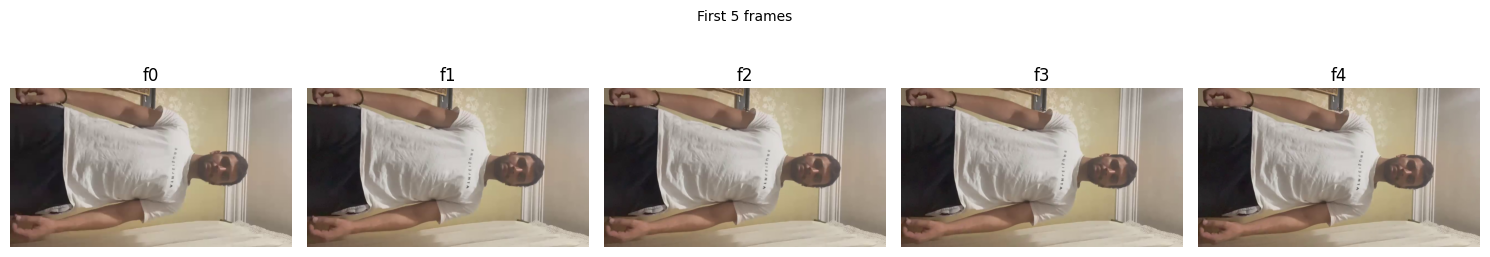


── Predictions [TTA×5] ──────────────────────
  now                    [HAND]  27.9%  ████████
  letter                 [POSE]  22.1%  ██████
  doctor                 [POSE]  9.6%  ██ ⚠️ low confidence
  time                   [POSE]  3.9%  █ ⚠️ low confidence
  change                 [HAND]  1.5%   ⚠️ low confidence

✅ Result: "now" (27.9%)


In [ ]:
# CELL 7 — Run Inference ▶️
# ── عدّل المسار ده بس ──────────────────────────────────────────
video_path = r"C:\Users\Bavle\OneDrive\Desktop\now.mp4"# ← حط مسار الفيديو هنا
# ────────────────────────────────────────────────────────────────

word, conf = predict_video(
    video_path,
    top_k       = 5,
    use_tta     = True,
    flip        = False,
    show_frames = True,
)

Frames: 76 | 0-hand: 2 (3%)  1-hand: 72  2-hand: 2


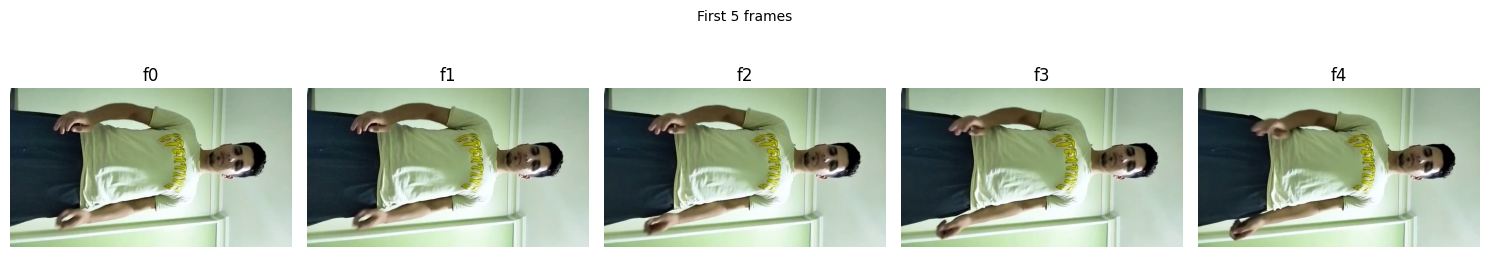


── Predictions [TTA×5] ──────────────────────
  man                    [POSE]  65.5%  ███████████████████
  black                  [POSE]  4.9%  █ ⚠️ low confidence
  like                   [POSE]  4.6%  █ ⚠️ low confidence
  table                  [HAND]  2.9%   ⚠️ low confidence
  woman                  [POSE]  1.8%   ⚠️ low confidence

✅ Result: "man" (65.5%)
Frames: 76 | 0-hand: 2 (3%)  1-hand: 72  2-hand: 2


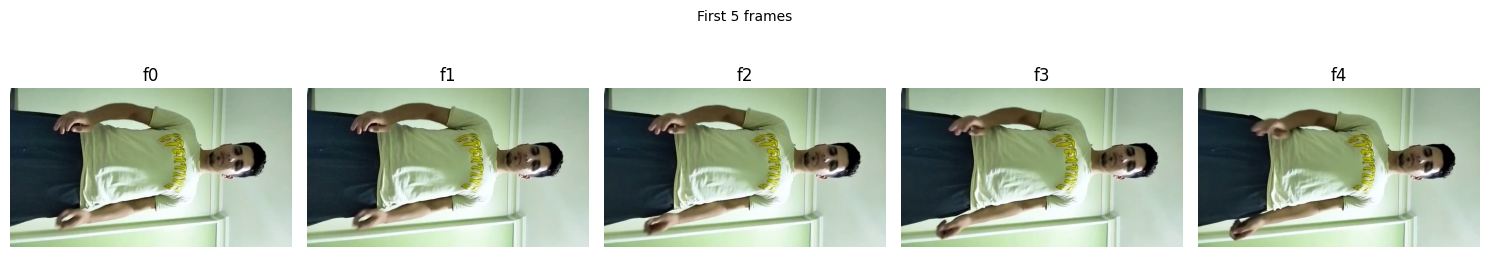


── Predictions [TTA×5] ──────────────────────
  man                    [POSE]  61.8%  ██████████████████
  like                   [POSE]  6.5%  █ ⚠️ low confidence
  black                  [POSE]  4.5%  █ ⚠️ low confidence
  woman                  [POSE]  4.1%  █ ⚠️ low confidence
  fine                   [POSE]  2.5%   ⚠️ low confidence

✅ Result: "man" (61.8%)


In [29]:
# في Cell 7 جرب الـ 3 دول وشوف مين أحسن
word, conf = predict_video(video_path, flip=False, use_tta=True)
word, conf = predict_video(video_path, flip=True,  use_tta=True)

In [30]:
cap = cv2.VideoCapture(video_path)
ok, frame = cap.read()
cap.release()

h, w = frame.shape[:2]
if h > w: frame = cv2.rotate(frame, cv2.ROTATE_90_CLOCKWISE)

sk = frame_to_skeleton(frame)
print("Sum dominant:", np.abs(sk[:21]).sum().round(4))
print("Sum passive: ", np.abs(sk[21:42]).sum().round(4))
print("Joint 0 dominant:", sk[0].round(4))

Sum dominant: 52.8558
Sum passive:  0.0
Joint 0 dominant: [0. 0. 0.]


In [19]:
cap = cv2.VideoCapture(r"C:\Users\Bavle\OneDrive\Desktop\books.mp4")
ok, frame = cap.read()
cap.release()

h, w = frame.shape[:2]
if h > w: frame = cv2.rotate(frame, cv2.ROTATE_90_CLOCKWISE)

sk = frame_to_skeleton(frame)
print("عندك:")
print("Sum dominant:", np.abs(sk[:21]).sum().round(4))
print("Sum passive: ", np.abs(sk[21:42]).sum().round(4))
print("Joint 0 dominant:", sk[0].round(4))

عندك:
Sum dominant: 38.1681
Sum passive:  0.0
Joint 0 dominant: [0. 0. 0.]


In [20]:
cap = cv2.VideoCapture(r"C:\Users\Bavle\OneDrive\Desktop\books.mp4")
ok, frame = cap.read()
cap.release()

h, w = frame.shape[:2]
if h > w: frame = cv2.rotate(frame, cv2.ROTATE_90_CLOCKWISE)

hands = extract_hands(frame, flip_hands=False)
for h in hands:
    print(f"Label: {h['label']} | Confidence: {h['confidence']:.2f}")

Label: Right | Confidence: 1.00


In [22]:
cap = cv2.VideoCapture(r"C:\Users\Bavle\OneDrive\Desktop\book.mp4")
ok, frame = cap.read()
cap.release()

h, w = frame.shape[:2]
if h > w: frame = cv2.rotate(frame, cv2.ROTATE_90_CLOCKWISE)

# اعكس الفريم
frame_flipped = cv2.flip(frame, 1)

hands_normal  = extract_hands(frame, flip_hands=False)
hands_flipped = extract_hands(frame_flipped, flip_hands=False)

print("Normal :", [(h['label'], round(h['confidence'],2)) for h in hands_normal])
print("Flipped:", [(h['label'], round(h['confidence'],2)) for h in hands_flipped])

Normal : [('Left', 0.92), ('Right', 0.99)]
Flipped: [('Right', 1.0)]
